# 05 — Data qubits are not equal: per-qubit error and where it comes from

The paper gives every data qubit the same flip probability per round.
In the circuit each qubit's error depends on how many CNOTs it sits in, at which end, and on
faults that spread to it from ancillas through later CNOTs (hook errors).

**Source:** `python -m qec_timing.studies.per_qubit` → `results/per_qubit/per_qubit.json`.
One round of the actual noisy circuit (premise settings: H2 ratios scaled to p2 = 5×10⁻³,
linear idle γ = 0.3 p2 on every qubit, X basis) in Stim's Pauli-frame simulator, 200k frames;
the Z component on each data qubit after the round. Split by keeping one noise class at a time.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
pq = json.loads((R / "per_qubit" / "per_qubit.json").read_text())
for r in pq["rows"]:
    z = {k: np.array(v) for k, v in r["z"].items()}
    print(f"d={r['d']} {r['gates']:<8} mean {z['total'].mean():.2e}  range {z['total'].min():.2e}-{z['total'].max():.2e}  "
          f"(x{z['total'].max() / z['total'].min():.1f})   shares: data {z['data'].sum() / z['total'].sum():.0%}, "
          f"propagated {z['ancilla'].sum() / z['total'].sum():.0%}, idle {z['idle'].sum() / z['total'].sum():.0%}")

d=3 textbook mean 1.38e-02  range 7.41e-03-2.15e-02  (x2.9)   shares: data 75%, propagated 7%, idle 18%
d=3 native   mean 1.31e-02  range 6.94e-03-2.04e-02  (x2.9)   shares: data 75%, propagated 16%, idle 11%
d=5 textbook mean 1.68e-02  range 7.42e-03-2.18e-02  (x2.9)   shares: data 76%, propagated 9%, idle 16%
d=5 native   mean 1.62e-02  range 6.98e-03-2.15e-02  (x3.1)   shares: data 74%, propagated 17%, idle 9%


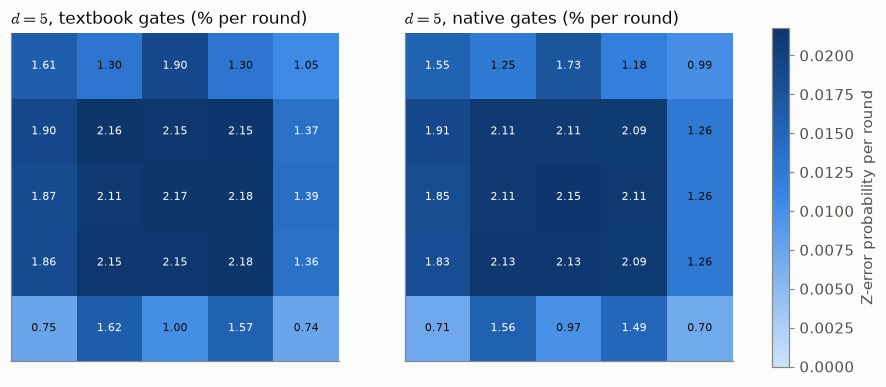

In [3]:
rows = [r for r in pq["rows"] if r["d"] == max(x["d"] for x in pq["rows"])]
fig, axes = plt.subplots(1, len(rows), figsize=(4.6 * len(rows), 4))
vmax = max(max(r["z"]["total"]) for r in rows)
for ax, r in zip(np.atleast_1d(axes), rows):
    d = r["d"]; M = np.full((d, d), np.nan)
    for (row, col), v in zip(r["grid"], r["z"]["total"]):
        M[int(row), int(col)] = v
    im = ax.imshow(M, cmap=P.sequential_cmap(), vmin=0, vmax=vmax)
    for i in range(d):
        for j in range(d):
            ax.text(j, i, f"{M[i, j] * 100:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if M[i, j] > 0.6 * vmax else P.INK)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(rf"$d = {d}$, {r['gates']} gates (% per round)", loc="left")
fig.colorbar(im, ax=axes, label="Z-error probability per round", fraction=0.03)
P.save(fig, "05_per_qubit_error_1")

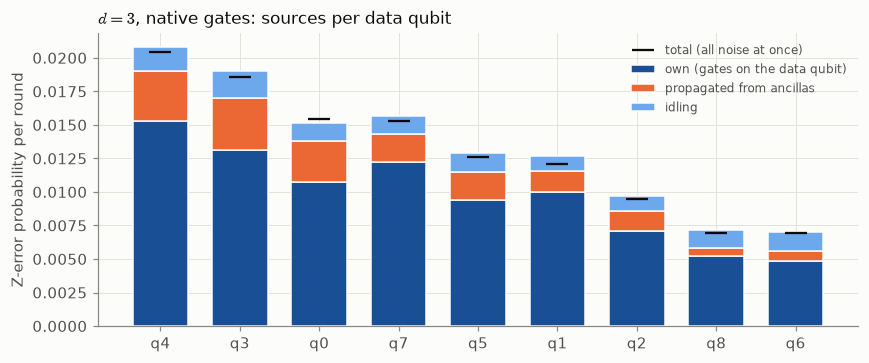

In [4]:
r = next(x for x in pq["rows"] if x["d"] == min(y["d"] for y in pq["rows"]) and x["gates"] == "native")
z = {k: np.array(v) for k, v in r["z"].items()}
order = np.argsort(-z["total"]); x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 3.4))
bottom = np.zeros(len(order))
for key, col, lab in (("data", P.SEQUENTIAL[5], "own (gates on the data qubit)"),
                      ("ancilla", P.SERIES[1], "propagated from ancillas"),
                      ("idle", P.SEQUENTIAL[2], "idling")):
    ax.bar(x, z[key][order], bottom=bottom, color=col, width=0.7, label=lab, edgecolor=P.SURFACE, linewidth=1)
    bottom += z[key][order]
ax.plot(x, z["total"][order], "_", color=P.INK, ms=14, mew=1.5, label="total (all noise at once)")
ax.set_xticks(x, [f"q{i}" for i in order]); ax.set_ylabel("Z-error probability per round")
ax.legend(fontsize=8); ax.set_title(rf"$d = {r['d']}$, native gates: sources per data qubit", loc="left")
fig.tight_layout()
P.save(fig, "05_per_qubit_error_2")

**Reading.**
- *Measured:* per-round error varies about 3× across data qubits: corner and edge qubits sit in
  fewer CNOTs than bulk qubits. The paper's model replaces this with one number.
- *Measured:* with native gates 16–17% of the data error arrives by propagation from ancillas
  (7–9% with textbook gates): the native CNOT decomposition puts noisy single-qubit gates on the
  ancillas, and their faults spread through later CNOTs.
- *Consequence:* a decoder or a model that assumes uniform, independent data errors misses
  structure that the circuit's own detector error model contains.
- *Note:* these are physical error frames; the effective p_data measured from detection events
  (notebook 04) is lower, because correlated pairs from one fault (hooks) count once there.